In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print("Current Folder:", os.getcwd())
print("\nFiles in Folder:")
print(os.listdir())

Current Folder: c:\Users\reyan\OneDrive\文档\MISSION 4 Retail Sales Performance Analytics

Files in Folder:
['Retail_Sales_Performance_Analytics.ipynb']


In [5]:
import pandas as pd

df = pd.read_csv(
    "Global_Superstore2.csv",
    encoding="latin1"
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [6]:
# Check Dataset Information

print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  str    
 2   Order Date      51290 non-null  str    
 3   Ship Date       51290 non-null  str    
 4   Ship Mode       51290 non-null  str    
 5   Customer ID     51290 non-null  str    
 6   Customer Name   51290 non-null  str    
 7   Segment         51290 non-null  str    
 8   City            51290 non-null  str    
 9   State           51290 non-null  str    
 10  Country         51290 non-null  str    
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  str    
 13  Region          51290 non-null  str    
 14  Product ID      51290 non-null  str    
 15  Category        51290 non-null  str    
 16  Sub-Category    51290 non-null  str    
 17  Product Name    51290

In [7]:
# Check Missing Values

missing_values = df.isnull().sum()

missing_df = pd.DataFrame({
    'Column': missing_values.index,
    'Missing Values': missing_values.values,
    'Missing Percentage': (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_df = missing_df[missing_df['Missing Values'] > 0]

display(missing_df)

,Column,Missing Values,Missing Percentage
11,Postal Code,41296,80.51


In [8]:
# Check Duplicate Records

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [9]:
# Check Unique Values in Important Columns

columns = [
    'Order ID',
    'Customer ID',
    'Country',
    'Region',
    'Category',
    'Sub-Category',
    'Segment',
    'Ship Mode'
]

for col in columns:
    print(col, ":", df[col].nunique())

Order ID : 25035
Customer ID : 1590
Country : 147
Region : 13
Category : 3
Sub-Category : 17
Segment : 3
Ship Mode : 4


In [10]:
# Convert Date Columns into Datetime Format

df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

print("Date Conversion Completed!")

print("Order Date Range:",
      df['Order Date'].min(),
      "to",
      df['Order Date'].max())

Date Conversion Completed!
Order Date Range: 2011-01-01 00:00:00 to 2014-12-31 00:00:00


In [11]:
# Handle Missing Values

df['Postal Code'] = df['Postal Code'].fillna(0)

print("Missing Values After Treatment:")
print(df.isnull().sum().sum())

Missing Values After Treatment:
0


In [12]:
# Feature Engineering

df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()

df['Shipping Days'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

print("New Features Created Successfully!")

display(df.head())

New Features Created Successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Year,Month,Month Name,Shipping Days
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,2309.650,7,0.0,762.1845,933.57,Critical,2012,7,July,0
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,3709.395,9,0.1,-288.7650,923.63,Critical,2013,2,February,2
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,5175.171,9,0.1,919.9710,915.49,Medium,2013,10,October,1
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,2892.510,5,0.1,-96.5400,910.16,Medium,2013,1,January,2
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,2832.960,8,0.0,311.5200,903.04,Critical,2013,11,November,1


In [13]:
print("Final Dataset Shape:", df.shape)

print("Total Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

print("Negative Sales Records:", (df['Sales'] < 0).sum())

print("Negative Profit Records:", (df['Profit'] < 0).sum())

Final Dataset Shape: (51290, 28)
Total Missing Values: 0
Total Duplicate Rows: 0
Negative Sales Records: 0
Negative Profit Records: 12544


In [14]:
# Overall Business KPIs

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_quantity = df['Quantity'].sum()

profit_margin = (total_profit / total_sales) * 100

print("========== BUSINESS PERFORMANCE ==========")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Profit Margin:", round(profit_margin, 2), "%")

========== BUSINESS PERFORMANCE ==========
Total Sales: 12642501.91
Total Profit: 1467457.29
Total Orders: 25035
Total Customers: 1590
Total Quantity Sold: 178312
Profit Margin: 11.61 %


In [15]:
# Yearly Sales and Profit

yearly_sales = df.groupby('Year').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

display(yearly_sales)

,Year,Sales,Profit
0,2011,2.259451e+06,248940.81154
1,2012,2.677439e+06,307415.27910
2,2013,3.405746e+06,406935.23018
3,2014,4.299866e+06,504165.97046


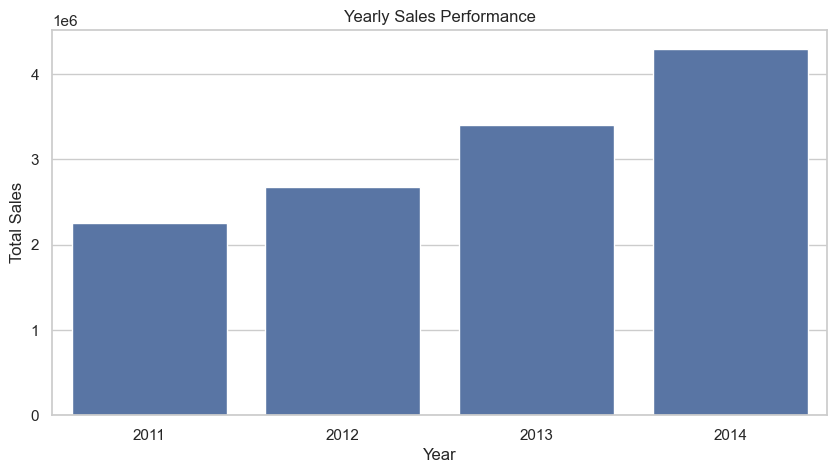

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_sales,
    x='Year',
    y='Sales'
)

plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.show()

In [17]:
category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

display(category_analysis)

,Category,Sales,Profit,Quantity
0,Furniture,4.110874e+06,285204.72380,34954
1,Office Supplies,3.787070e+06,518473.83430,108182
2,Technology,4.744557e+06,663778.73318,35176


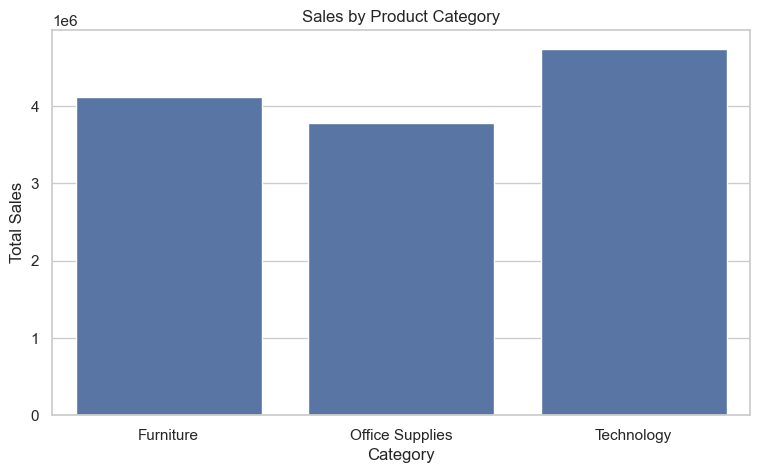

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x='Category',
    y='Sales'
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

In [19]:
region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

display(region_analysis)

,Region,Sales,Profit
0,Africa,7.837732e+05,88871.63100
1,Canada,6.692817e+04,17817.39000
2,Caribbean,3.242809e+05,34571.32104
3,Central,2.822303e+06,311403.98164
4,Central Asia,7.528266e+05,132480.18700
5,EMEA,8.061613e+05,43897.97100
6,East,6.787812e+05,91522.78000
7,North,1.248166e+06,194597.95252
8,North Asia,8.483098e+05,165578.42100
9,Oceania,1.100185e+06,120089.11200


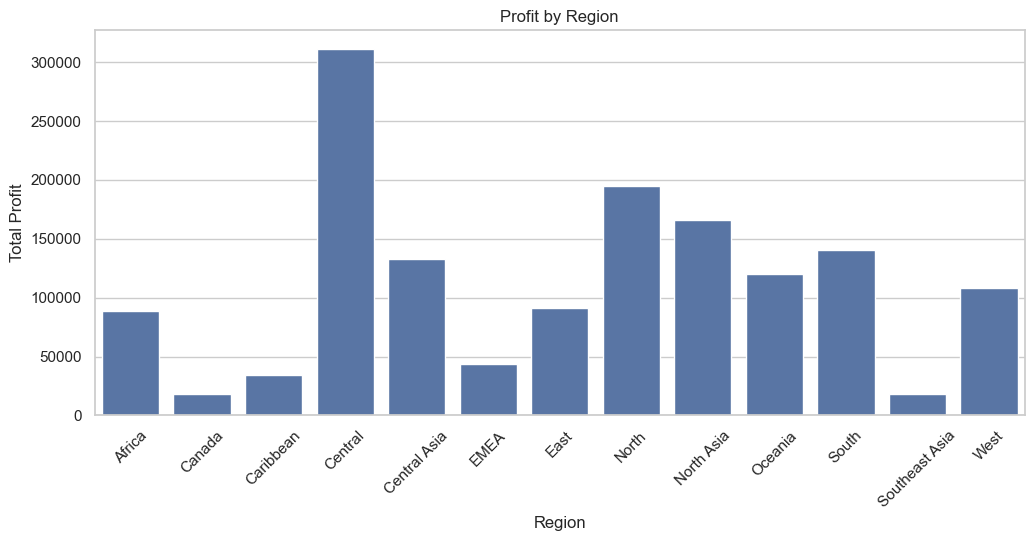

In [20]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=region_analysis,
    x='Region',
    y='Profit'
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

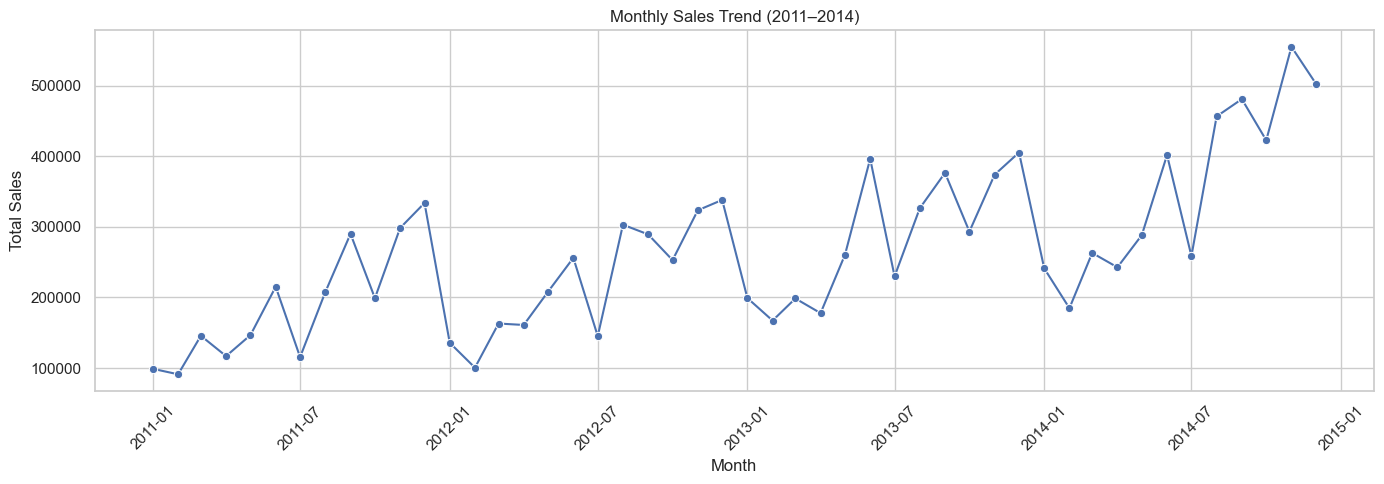

In [21]:
monthly_sales = df.groupby(
    ['Year', 'Month']
)['Sales'].sum().reset_index()

monthly_sales['Date'] = pd.to_datetime(
    monthly_sales['Year'].astype(str) + '-' +
    monthly_sales['Month'].astype(str) + '-01'
)

monthly_sales = monthly_sales.sort_values('Date')

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='Date',
    y='Sales',
    marker='o'
)

plt.title("Monthly Sales Trend (2011–2014)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
segment_analysis = df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

display(segment_analysis)

,Segment,Sales,Profit,Order ID
0,Consumer,6.507949e+06,749239.78206,13104
1,Corporate,3.824698e+06,441208.32866,7673
2,Home Office,2.309855e+06,277009.18056,4687


In [23]:
segment_analysis = df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique',
    'Customer ID': 'nunique'
}).reset_index()

display(segment_analysis)

,Segment,Sales,Profit,Order ID,Customer ID
0,Consumer,6.507949e+06,749239.78206,13104,818
1,Corporate,3.824698e+06,441208.32866,7673,476
2,Home Office,2.309855e+06,277009.18056,4687,296


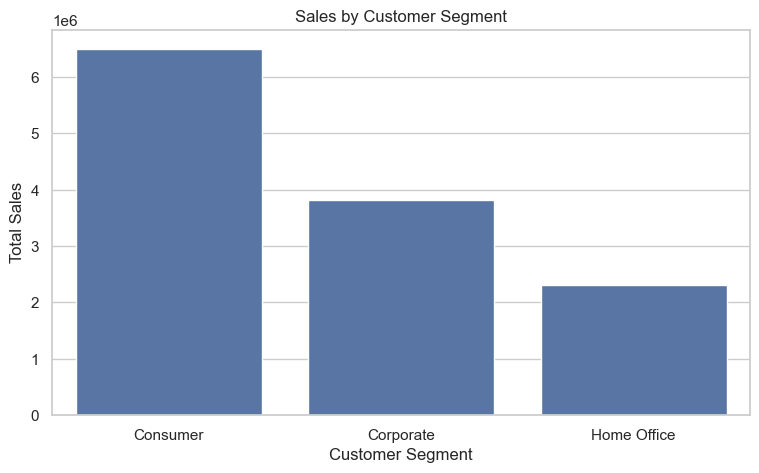

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis,
    x='Segment',
    y='Sales'
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.show()

In [25]:
shipping_analysis = df.groupby('Ship Mode').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

display(shipping_analysis)

,Ship Mode,Sales,Profit,Order ID
0,First Class,1.830976e+06,208104.67520,3821
1,Same Day,6.672020e+05,76173.06780,1347
2,Second Class,2.565672e+06,292583.52708,5119
3,Standard Class,7.578652e+06,890596.02120,15154


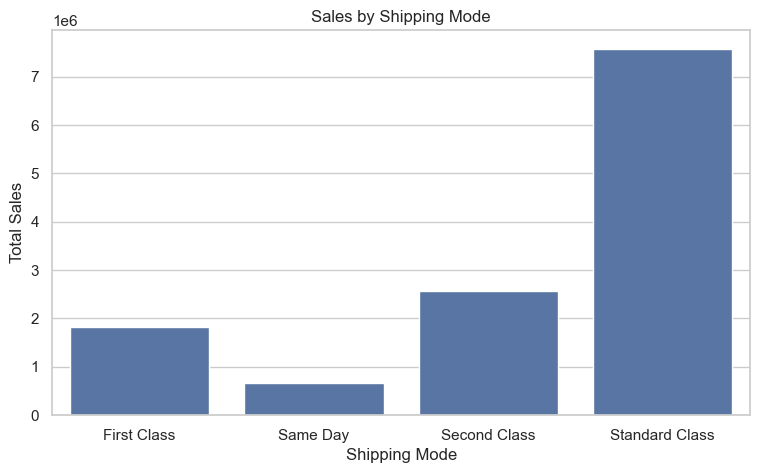

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipping_analysis,
    x='Ship Mode',
    y='Sales'
)

plt.title("Sales by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Sales")

plt.show()

In [27]:
discount_analysis = df.groupby('Discount').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

display(discount_analysis)

,Discount,Sales,Profit,Quantity
0,0.000,6.992411e+06,1.770695e+06,98768
1,0.002,2.613956e+05,5.797658e+04,1657
2,0.070,1.216169e+05,2.114850e+04,533
3,0.100,1.579606e+06,2.590642e+05,15417
4,0.150,3.060298e+05,2.737590e+04,2021
5,0.170,2.473992e+05,2.816307e+04,2720
6,0.200,1.203832e+06,1.177159e+05,18653
7,0.202,1.621565e+04,-5.952727e+02,135
8,0.250,8.805535e+04,8.005875e+02,826
9,0.270,8.935167e+04,-1.675079e+03,1453


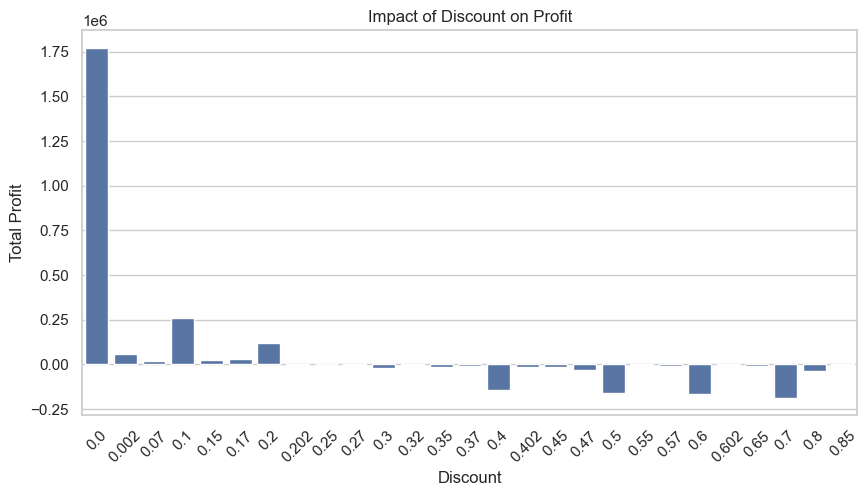

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x='Discount',
    y='Profit'
)

plt.title("Impact of Discount on Profit")
plt.xlabel("Discount")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)
plt.show()

In [29]:
country_analysis = df.groupby('Country')['Sales'].sum()

top_countries = country_analysis.sort_values(
    ascending=False
).head(10).reset_index()

display(top_countries)

,Country,Sales
0,United States,2.297201e+06
1,Australia,9.252359e+05
2,France,8.589311e+05
3,China,7.005620e+05
4,Germany,6.288400e+05
5,Mexico,6.225906e+05
6,India,5.896501e+05
7,United Kingdom,5.285763e+05
8,Indonesia,4.048875e+05
9,Brazil,3.611064e+05


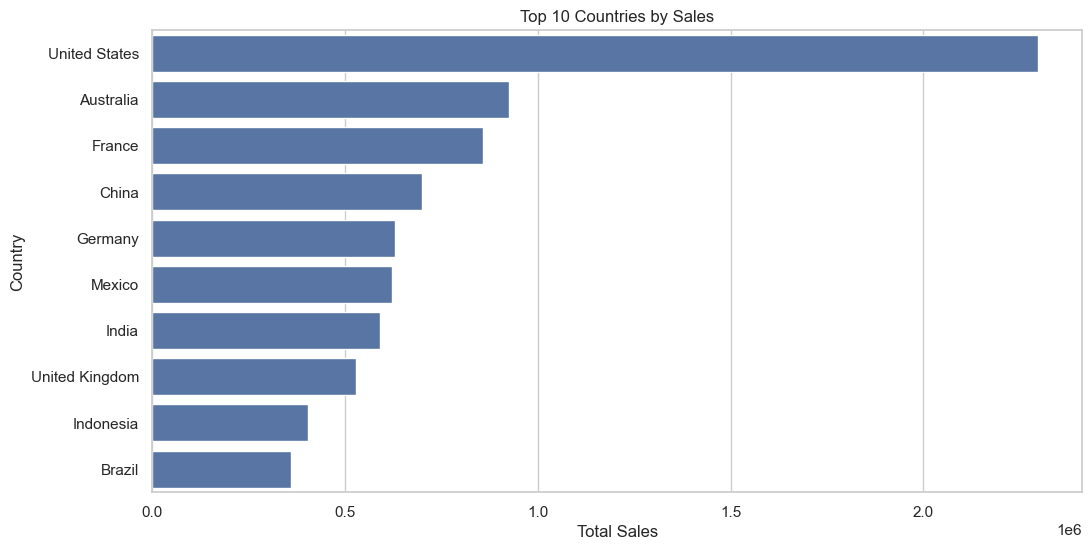

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Sales',
    y='Country'
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")

plt.show()

In [31]:
# Export cleaned dataset for SQL analysis

df.to_csv(
    "Global_Superstore_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [32]:
import os

print("Current Folder:", os.getcwd())

print("\nExported File Exists:",
      os.path.exists("Global_Superstore_Cleaned.csv"))

print("\nFile Size:",
      round(os.path.getsize("Global_Superstore_Cleaned.csv") / 1024 / 1024, 2),
      "MB")

Current Folder: c:\Users\reyan\OneDrive\文档\MISSION 4 Retail Sales Performance Analytics

Exported File Exists: True

File Size: 12.55 MB
